# 02 · Experiments

The station-correction models under different settings: learning rate, terrain resolution,
network type, input forecasts, observations as input and the training stations. How the models
train is in `01_training.ipynb`.

**Score.** Every configuration is scored on the same test: the 99 Frost stations of Nordland,
Troms and Finnmark, test runs 2025-04-01 – 2025-09-12 (00 and 12 UTC, leads 0–66 h every 6 h).
Each station is predicted by the run of the fold that did not train on its group. The metric is the
vector RMSE of the 10 m wind, as a **change in % against the IFS + AIFS mean** at the station
(no correction). Negative = better.

**Seeds.** Some configurations were trained with 3 seeds, the others with seed 0 only. The seed
spread is shown wherever there is one; it is the yardstick for every difference below.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import runlib as R

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3, 'axes.spines.top': False,
                     'axes.spines.right': False, 'legend.frameon': False})
sc = R.Scorer()
L = sc.leads
_cache = {}
def res(pattern, group='ecmwf'):
    # (seeds, leads) change in % vs the IFS + AIFS mean; one row per seed with all 5 folds
    if (pattern, group) not in _cache:
        _cache[(pattern, group)] = sc.score(pattern, group)
    return _cache[(pattern, group)]

def row(label, pattern, group='ecmwf'):
    c = res(pattern, group)
    return {'configuration': label, 'seeds': len(c), 'mean (%)': c.mean(), 'seed sd': c.mean(1).std() if len(c) > 1 else np.nan,
            '+6 h': c[:, 1].mean(), '+24 h': c[:, 4].mean(), '+48 h': c[:, 8].mean(), '+66 h': c[:, -1].mean()}

def bars(ax, items, title, ref=None):
    # horizontal bars: mean over seeds; dots: the individual seeds; grey band / dashed line: seed range / seed 0 of `ref`
    for i, (lab, pat, *g) in enumerate(items):
        c = res(pat, *g).mean(1)
        ax.barh(i, c.mean(), color='#0b6aa2' if len(c) > 1 else '#7fb3d5', height=.6)
        ax.plot(c, np.full(len(c), i), 'o', color='#14232e', ms=3.5)
        ax.text(max(c.mean(), 0) + .08, i, f'{c.mean():.2f}', va='center', ha='left', fontsize=8)
    if ref is not None:
        r = res(ref).mean(1)
        ax.axvspan(r.min(), r.max(), color='0.5', alpha=.15, lw=0)
        ax.axvline(r[0], color='0.3', ls='--', lw=1)
    ax.set_xlim(right=max(ax.get_xlim()[1], .7))
    ax.set_yticks(range(len(items)), [it[0] for it in items], fontsize=9)
    ax.invert_yaxis(); ax.axvline(0, color='0.3', lw=.8)
    ax.set(title=title, xlabel='RMSE change vs IFS + AIFS (%)')

r0 = sc.r0
print(f'reference: IFS + AIFS mean, vector RMSE {r0.mean():.2f} m/s (mean over leads; {r0[0]:.2f} at +0 h, {r0[-1]:.2f} at +66 h); '
      f'{sc.te.sum()} test runs')

reference: IFS + AIFS mean, vector RMSE 3.49 m/s (mean over leads; 3.35 at +0 h, 3.66 at +66 h); 328 test runs


## 1 · Learning rate

SFNO + MLP with the 1 km terrain descriptors at peak learning rates $10^{-3}$, $10^{-4}$,
$3\cdot10^{-5}$ and $10^{-5}$, and the variants with finer terrain (section 2) at the rates they were
trained with. MLP and FNO + MLP were trained at $10^{-3}$ and $10^{-5}$.

,seeds,mean (%),seed sd,+6 h,+24 h,+48 h,+66 h
configuration,,,,,,,
"SFNO + MLP, 1 km terrain · 1e-05",3,-4.39,0.76,-4.98,-4.67,-4.16,-3.48
"SFNO + MLP, 1 km terrain · 3e-05",3,-4.25,0.76,-4.82,-4.52,-4.04,-3.36
"SFNO + MLP, 1 km terrain · 0.0001",1,-4.32,NaN,-4.90,-4.59,-4.11,-3.41
"SFNO + MLP, 1 km terrain · 0.001",3,-4.07,0.80,-4.65,-4.41,-3.89,-3.09
+ 100 m cell statistics · 3e-05,1,-2.60,NaN,-3.07,-2.76,-2.45,-2.03
+ 100 m cell statistics · 0.0001,1,-2.73,NaN,-3.24,-2.89,-2.58,-2.17
+ 100 m cell statistics · 0.001,1,-3.38,NaN,-3.90,-3.75,-3.32,-2.38
+ 100 m point and cell · 3e-05,1,-3.21,NaN,-3.62,-3.53,-3.13,-2.40
+ 100 m point and cell · 0.0001,1,-2.80,NaN,-3.14,-3.11,-2.72,-2.08


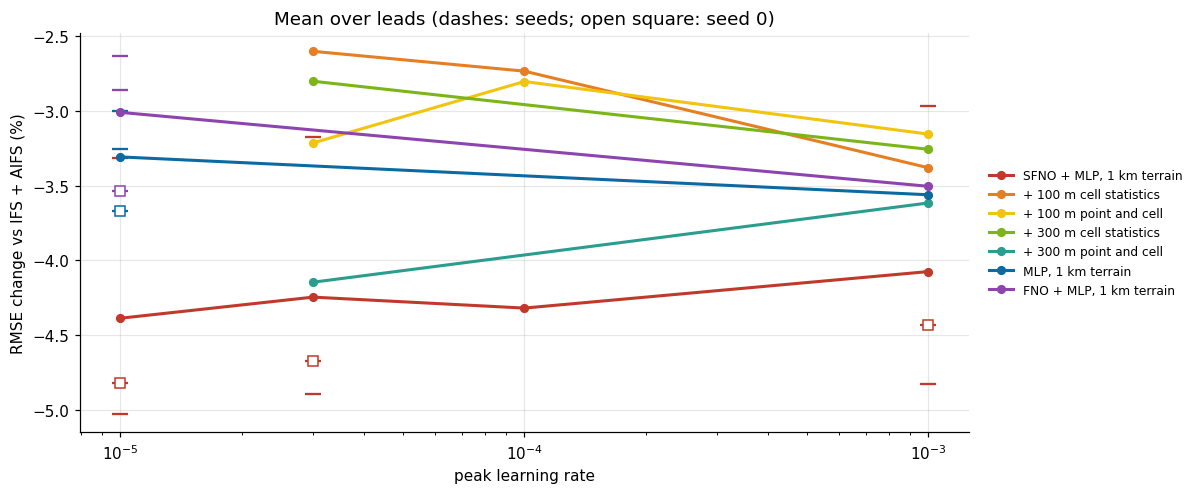

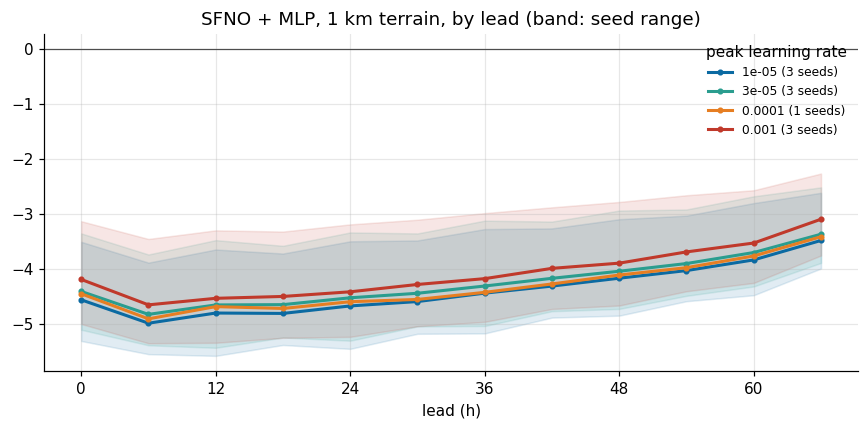

In [2]:
LRS = {'SFNO + MLP, 1 km terrain': {1e-3: 'sfno_terrain_g{k}_s{s}', 1e-4: 'sfno_terrain_g{k}_s{s}_lr0.0001',
                                    3e-5: 'sfno_terrain_g{k}_s{s}_lr3e-05', 1e-5: 'sfno_terrain_g{k}_s{s}_lr1e-05'},
       '+ 100 m cell statistics': {1e-3: 'sfno_terrain_g{k}_s{s}_c100', 1e-4: 'sfno_terrain_g{k}_s{s}_c100_lr0.0001',
                                   3e-5: 'sfno_terrain_g{k}_s{s}_c100_lr3e-05'},
       '+ 100 m point and cell': {1e-3: 'sfno_terrain_g{k}_s{s}_pc100', 1e-4: 'sfno_terrain_g{k}_s{s}_pc100_lr0.0001',
                                  3e-5: 'sfno_terrain_g{k}_s{s}_pc100_lr3e-05'},
       '+ 300 m cell statistics': {1e-3: 'sfno_terrain_g{k}_s{s}_c300', 3e-5: 'sfno_terrain_g{k}_s{s}_c300_lr3e-05'},
       '+ 300 m point and cell': {1e-3: 'sfno_terrain_g{k}_s{s}_pc300', 3e-5: 'sfno_terrain_g{k}_s{s}_pc300_lr3e-05'},
       'MLP, 1 km terrain': {1e-3: 'point_terrain_g{k}_s{s}', 1e-5: 'point_terrain_g{k}_s{s}_lr1e-05'},
       'FNO + MLP, 1 km terrain': {1e-3: 'fno_terrain_g{k}_s{s}', 1e-5: 'fno_terrain_g{k}_s{s}_lr1e-05'}}

fig, ax0 = plt.subplots(figsize=(11, 4.6))
ax = [ax0]
for (lab, d), col in zip(LRS.items(), ['#c0392b', '#e67e22', '#f1c40f', '#7cb518', '#2a9d8f', '#0b6aa2', '#8e44ad']):
    lrs = sorted(d)
    cs = [res(d[lr]).mean(1) for lr in lrs]
    ax[0].plot(lrs, [c.mean() for c in cs], '-o', color=col, lw=2, ms=5, label=lab)
    for lr, c in zip(lrs, cs):
        if len(c) > 1:
            ax[0].plot([lr] * len(c), c, '_', color=col, ms=10, mew=1.5)
            ax[0].plot(lr, c[0], 's', color=col, mfc='white', ms=6)
ax[0].set(xscale='log', xlabel='peak learning rate', ylabel='RMSE change vs IFS + AIFS (%)',
          title='Mean over leads (dashes: seeds; open square: seed 0)')
ax[0].legend(fontsize=8, loc='center left', bbox_to_anchor=(1.01, .5))
plt.tight_layout()

fig, a1 = plt.subplots(figsize=(8, 4))
ax = [None, a1]
d = LRS['SFNO + MLP, 1 km terrain']
for lr, col in zip(sorted(d), ['#0b6aa2', '#2a9d8f', '#e67e22', '#c0392b']):
    c = res(d[lr])
    ax[1].plot(L, c.mean(0), '-o', ms=3, lw=2, color=col, label=f'{lr:g} ({len(c)} seeds)')
    if len(c) > 1: ax[1].fill_between(L, c.min(0), c.max(0), color=col, alpha=.12)
ax[1].set(xlabel='lead (h)', xticks=L[::2], title='SFNO + MLP, 1 km terrain, by lead (band: seed range)')
ax[1].legend(fontsize=8, title='peak learning rate'); ax[1].axhline(0, color='0.3', lw=.8)
plt.tight_layout()

pd.DataFrame([row(f'{lab} · {lr:g}', p) for lab, d in LRS.items() for lr, p in sorted(d.items())]).set_index('configuration').round(2)

The seeds differ more than the learning rates. Paired by seed (same seed, different rate), the
mean change of the models trained with 3 seeds:

In [3]:
pd.DataFrame({f'{lab} · {lr:g}': pd.Series(res(p).mean(1), index=[f'seed {s}' for s in sc.seeds(p)])
              for lab in ('SFNO + MLP, 1 km terrain', 'MLP, 1 km terrain', 'FNO + MLP, 1 km terrain')
              for lr, p in sorted(LRS[lab].items())}).T.round(2)

,seed 0,seed 1,seed 2
"SFNO + MLP, 1 km terrain · 1e-05",-4.82,-5.03,-3.31
"SFNO + MLP, 1 km terrain · 3e-05",-4.67,-4.89,-3.17
"SFNO + MLP, 1 km terrain · 0.0001",-4.32,NaN,NaN
"SFNO + MLP, 1 km terrain · 0.001",-4.43,-4.83,-2.96
"MLP, 1 km terrain · 1e-05",-3.67,-3.25,-3.00
"MLP, 1 km terrain · 0.001",-3.56,NaN,NaN
"FNO + MLP, 1 km terrain · 1e-05",-3.53,-2.64,-2.86
"FNO + MLP, 1 km terrain · 0.001",-3.50,NaN,NaN


## 2 · Terrain resolution

All variants use the 28 descriptors of the 1 km grid (elevation, slope, aspect, relative height
over 1, 5, 10 and 30 km, land fraction, and the upwind shelter $S_x$ within 1 and 10 km in 8
directions). The finer variants add, from a 100 m (or 300 m) elevation grid built from the
Kartverket 50 m DTM:

| variant | added inputs | exists at every 1 km cell? |
|---|---|---|
| **+ 100 m station point (50 m DTM)** | slope, relative height, relief and $S_x$ (300 m, 1 km) at the station itself, from DTM patches around the stations | no |
| **+ 100 m cell statistics** | the mean of the 100 m fields over the station's 1 km cell, plus the sub-cell relief | yes |
| **+ 100 m point and cell** | both of the above, the point from the 100 m grid | no |
| **+ 300 m cell / point and cell** | the same from a 300 m grid ($S_x$ within 900 m and 3 km) | cell: yes |

The finer variants were trained with seed 0 only, at $10^{-3}$ and $3\cdot10^{-5}$ (section 1 has
all rates). In the bar charts, dots are seeds; the grey band is the range of the three seeds of the
1 km model at the same rate and the dashed line its seed 0, the fair partner of a seed-0 variant.

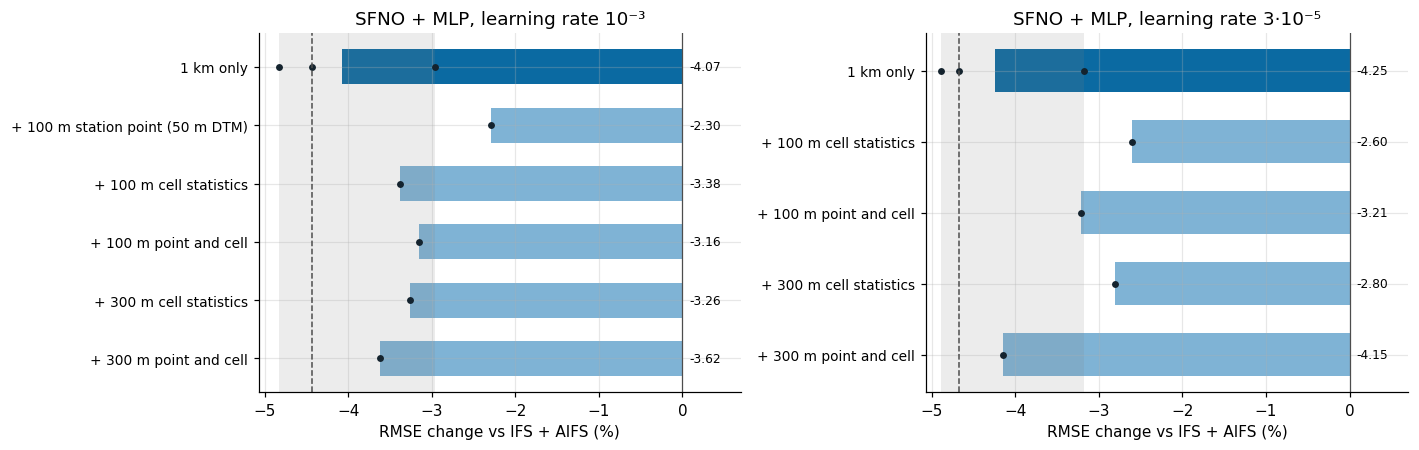

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), sharex=True)
for a, lr, sfx in zip(ax, ('10⁻³', '3·10⁻⁵'), ('', '_lr3e-05')):
    items = [('1 km only', f'sfno_terrain_g{{k}}_s{{s}}{sfx}'),
             ('+ 100 m station point (50 m DTM)', 'sfno_terrain_g{k}_s{s}_t100') if not sfx else None,
             ('+ 100 m cell statistics', f'sfno_terrain_g{{k}}_s{{s}}_c100{sfx}'),
             ('+ 100 m point and cell', f'sfno_terrain_g{{k}}_s{{s}}_pc100{sfx}'),
             ('+ 300 m cell statistics', f'sfno_terrain_g{{k}}_s{{s}}_c300{sfx}'),
             ('+ 300 m point and cell', f'sfno_terrain_g{{k}}_s{{s}}_pc300{sfx}')]
    bars(a, [i for i in items if i], f'SFNO + MLP, learning rate {lr}', ref=items[0][1])
plt.tight_layout()

The same, each variant against the 1 km model **with the same seed** (seed 0) at the same rate,
in percentage points (negative = the variant is better):

In [5]:
TV = {'+ 100 m station point (50 m DTM)': '_t100', '+ 100 m cell statistics': '_c100', '+ 100 m point and cell': '_pc100',
      '+ 300 m cell statistics': '_c300', '+ 300 m point and cell': '_pc300'}
LRSFX = {1e-3: '', 1e-4: '_lr0.0001', 3e-5: '_lr3e-05'}
tab = {}
for lab, t in TV.items():
    for lr, l in LRSFX.items():
        if R.run_names(f'sfno_terrain_g{{k}}_s{{s}}{t}{l}'):
            tab.setdefault(lab, {})[f'{lr:g}'] = res(f'sfno_terrain_g{{k}}_s{{s}}{t}{l}')[0].mean() - res(f'sfno_terrain_g{{k}}_s{{s}}{l}')[0].mean()
pd.DataFrame(tab).T.round(2)

,0.001,0.0001,3e-05
+ 100 m station point (50 m DTM),2.13,NaN,NaN
+ 100 m cell statistics,1.05,1.58,2.07
+ 100 m point and cell,1.27,1.52,1.46
+ 300 m cell statistics,1.17,NaN,1.87
+ 300 m point and cell,0.81,NaN,0.52


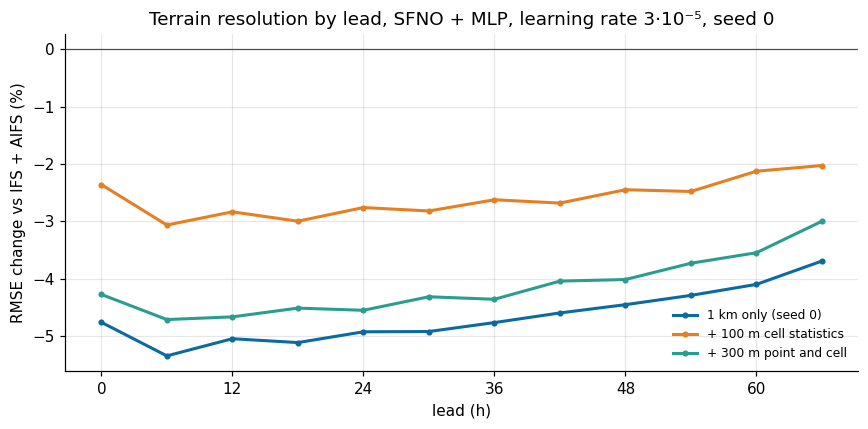

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
for lab, p, col in [('1 km only (seed 0)', 'sfno_terrain_g{k}_s{s}_lr3e-05', '#0b6aa2'),
                    ('+ 100 m cell statistics', 'sfno_terrain_g{k}_s{s}_c100_lr3e-05', '#e67e22'),
                    ('+ 300 m point and cell', 'sfno_terrain_g{k}_s{s}_pc300_lr3e-05', '#2a9d8f')]:
    ax.plot(L, res(p)[0], '-o', ms=3, lw=2, color=col, label=lab)
ax.set(xlabel='lead (h)', ylabel='RMSE change vs IFS + AIFS (%)', xticks=L[::2],
       title='Terrain resolution by lead, SFNO + MLP, learning rate 3·10⁻⁵, seed 0')
ax.axhline(0, color='0.3', lw=.8); ax.legend(fontsize=8)
plt.tight_layout()

## 3 · Network type

All with the 1 km terrain descriptors and IFS + AIFS inputs, learning rate $10^{-5}$, 3 seeds.
The operator reads the 0.25° fields and passes 32 latent channels to the MLP at the point;
*MLP* has no operator; *SFNO + LocalNO* replaces the MLP by a local operator on 33 × 33 km patches of
1 km cells. For comparison, the operators of the first stage (no terrain descriptors; the station
obs-forecast at issue time as input instead; learning rate $10^{-3}$, seed 0).

,parameters,seeds,mean (%),seed sd,+6 h,+24 h,+48 h,+66 h
configuration,,,,,,,,
SFNO + MLP,606434,3,-4.39,0.76,-4.98,-4.67,-4.16,-3.48
MLP,22018,3,-3.31,0.28,-3.89,-3.69,-3.13,-2.26
FNO + MLP,4538594,3,-3.01,0.38,-3.42,-3.23,-2.85,-2.35
TFNO + MLP,2003570,3,-2.95,0.25,-3.31,-3.25,-2.88,-2.22
UNO + MLP,8883170,3,-1.91,0.42,-2.04,-2.24,-1.96,-1.31
SFNO + LocalNO (1 km patches),701314,3,-1.14,0.08,-1.37,-1.43,-1.07,-0.53
FNO (no terrain),4510146,1,-0.92,NaN,-0.99,-1.05,-0.93,-0.68
SFNO (no terrain),577986,1,-0.71,NaN,-0.71,-0.92,-0.85,-0.39
TFNO (no terrain),1975122,1,-0.90,NaN,-0.99,-0.96,-0.86,-0.80


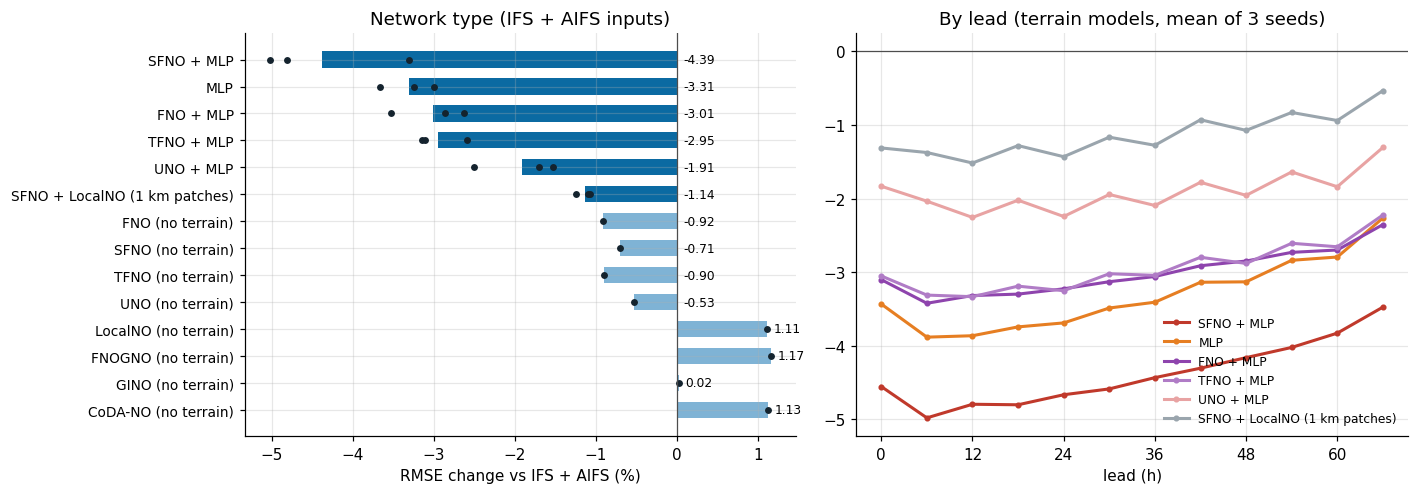

In [7]:
NETS = [('SFNO + MLP', 'sfno_terrain_g{k}_s{s}_lr1e-05'), ('MLP', 'point_terrain_g{k}_s{s}_lr1e-05'),
        ('FNO + MLP', 'fno_terrain_g{k}_s{s}_lr1e-05'), ('TFNO + MLP', 'tfno_terrain_g{k}_s{s}_lr1e-05'),
        ('UNO + MLP', 'uno_terrain_g{k}_s{s}_lr1e-05'), ('SFNO + LocalNO (1 km patches)', 'sfno_terrain_g{k}_s{s}_lno_lr1e-05')]
STAGE1 = [(f'{n} (no terrain)', f'{m}_excluding_g{{k}}_s{{s}}')
          for m, n in (('fno', 'FNO'), ('sfno', 'SFNO'), ('tfno', 'TFNO'), ('uno', 'UNO'), ('localno', 'LocalNO'),
                       ('fnogno', 'FNOGNO'), ('gino', 'GINO'), ('codano', 'CoDA-NO'))]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={'width_ratios': [1, 1]})
bars(ax[0], NETS + STAGE1, 'Network type (IFS + AIFS inputs)')
for (lab, p), col in zip(NETS, ['#c0392b', '#e67e22', '#8e44ad', '#b07cc6', '#e8a3a3', '#9aa5ad']):
    c = res(p); ax[1].plot(L, c.mean(0), '-o', ms=3, lw=2, color=col, label=lab)
ax[1].set(xlabel='lead (h)', xticks=L[::2], title='By lead (terrain models, mean of 3 seeds)')
ax[1].axhline(0, color='0.3', lw=.8); ax[1].legend(fontsize=8)
plt.tight_layout()

npar = {lab: int(R.histories(p).n_params.iloc[0]) for lab, p in NETS + STAGE1}
t = pd.DataFrame([row(lab, p) for lab, p in NETS + STAGE1]).set_index('configuration')
t.insert(0, 'parameters', pd.Series(npar))
t.round(2)

## 4 · Input forecasts

The same three networks with IFS + AIFS inputs and with four models (IFS, GFS and the 2.5 km
regional models MEPS and AROME-Arctic), learning rate $10^{-5}$, 3 seeds. The dashed line is the
uncorrected four-model mean. Every change is against the IFS + AIFS mean.

,seeds,mean (%),seed sd,+6 h,+24 h,+48 h,+66 h
configuration,,,,,,,
SFNO + MLP · IFS + AIFS inputs,3,-4.39,0.76,-4.98,-4.67,-4.16,-3.48
FNO + MLP · IFS + AIFS inputs,3,-3.01,0.38,-3.42,-3.23,-2.85,-2.35
MLP · IFS + AIFS inputs,3,-3.31,0.28,-3.89,-3.69,-3.13,-2.26
SFNO + MLP · IFS + GFS + MEPS + AROME-Arctic inputs,3,-9.03,0.19,-12.00,-10.19,-7.45,-5.37
FNO + MLP · IFS + GFS + MEPS + AROME-Arctic inputs,3,-8.86,0.38,-11.53,-10.24,-7.46,-5.16
MLP · IFS + GFS + MEPS + AROME-Arctic inputs,3,-9.71,0.25,-12.73,-11.03,-8.13,-5.78
"four-model mean, uncorrected",0,-6.43,NaN,-8.93,-7.67,-4.95,-3.21


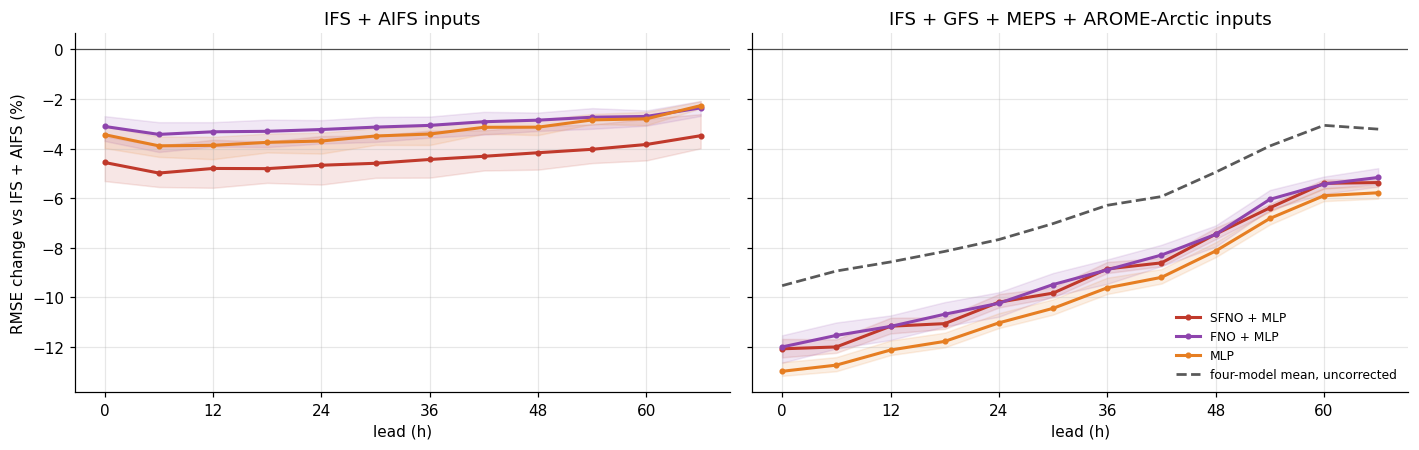

In [8]:
INP = [('SFNO + MLP', 'sfno', '#c0392b'), ('FNO + MLP', 'fno', '#8e44ad'), ('MLP', 'point', '#e67e22')]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
rows = []
for a, g, sfx, t in zip(ax, ('ecmwf', 'nwp'), ('', '_nwp'), ('IFS + AIFS inputs', 'IFS + GFS + MEPS + AROME-Arctic inputs')):
    for lab, m, col in INP:
        c = res(f'{m}_terrain_g{{k}}_s{{s}}{sfx}_lr1e-05', g)
        a.plot(L, c.mean(0), '-o', ms=3, lw=2, color=col, label=lab)
        a.fill_between(L, c.min(0), c.max(0), color=col, alpha=.12)
        rows.append(row(f'{lab} · {t}', f'{m}_terrain_g{{k}}_s{{s}}{sfx}_lr1e-05', g))
    a.axhline(0, color='0.3', lw=.8); a.set(title=t, xlabel='lead (h)', xticks=L[::2])
raw = sc.change(sc.base['nwp'])
ax[1].plot(L, raw, '--', color='0.35', lw=1.8, label='four-model mean, uncorrected')
ax[0].set_ylabel('RMSE change vs IFS + AIFS (%)'); ax[1].legend(fontsize=8)
plt.tight_layout()
rows.append({'configuration': 'four-model mean, uncorrected', 'seeds': 0, 'mean (%)': raw.mean(),
             '+6 h': raw[1], '+24 h': raw[4], '+48 h': raw[8], '+66 h': raw[-1]})
pd.DataFrame(rows).set_index('configuration').round(2)

## 5 · Observations as input

*Terrain + obs* adds the obs-forecast of the other stations at issue time (observation minus the
forecast of the previous run), spread onto the operator grid and, for the MLP, inverse-distance
weighted to the point. During training one whole station group is hidden from the input and scored,
as in the test. Learning rate $10^{-3}$, seed 0.

,terrain,terrain + obs,difference
configuration,,,
"SFNO + MLP, 1 km",-4.43,-4.61,-0.18
"SFNO + MLP, + 100 m station point",-2.30,-3.48,-1.18
"SFNO + MLP, + 100 m cell",-3.38,-2.87,0.51
"SFNO + MLP, + 100 m point and cell",-3.16,-3.94,-0.78
"SFNO + MLP, 178 training stations",-4.81,-3.70,1.11
"SFNO + MLP, 196 training stations",-5.19,-4.26,0.93
"MLP, 1 km",-3.56,-4.62,-1.06


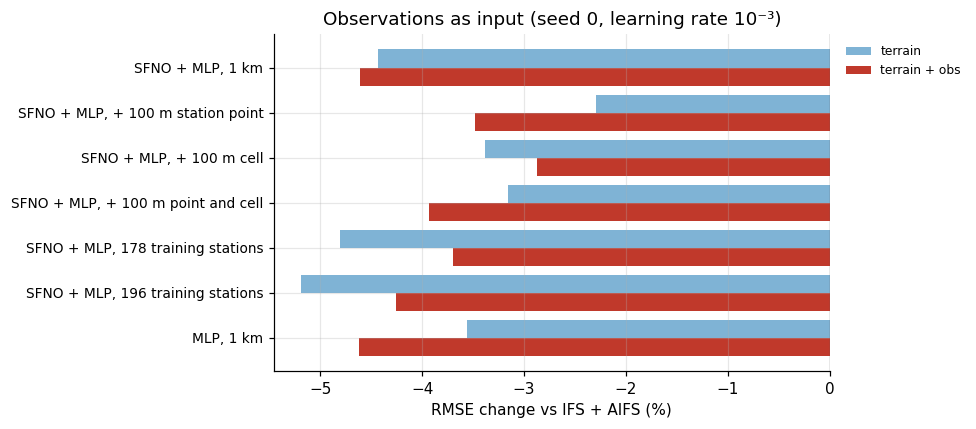

In [9]:
PAIRS = [('SFNO + MLP, 1 km', ''), ('SFNO + MLP, + 100 m station point', '_t100'),
         ('SFNO + MLP, + 100 m cell', '_c100'), ('SFNO + MLP, + 100 m point and cell', '_pc100'),
         ('SFNO + MLP, 178 training stations', '_ext'), ('SFNO + MLP, 196 training stations', '_all')]
rows = []
for lab, sfx in PAIRS:
    a = res(f'sfno_terrain_g{{k}}_s{{s}}{sfx}')[:1].mean(); b = res(f'sfno_terrainobs_g{{k}}_s{{s}}{sfx}')[:1].mean()
    rows.append({'configuration': lab, 'terrain': a, 'terrain + obs': b})
a = res('point_terrain_g{k}_s{s}')[:1].mean(); b = res('point_terrainobs_g{k}_s{s}')[:1].mean()
rows.append({'configuration': 'MLP, 1 km', 'terrain': a, 'terrain + obs': b})
t = pd.DataFrame(rows).set_index('configuration')
fig, ax = plt.subplots(figsize=(9, 4))
y = np.arange(len(t))
ax.barh(y - .2, t['terrain'], .4, color='#7fb3d5', label='terrain')
ax.barh(y + .2, t['terrain + obs'], .4, color='#c0392b', label='terrain + obs')
ax.set_yticks(y, t.index, fontsize=9); ax.invert_yaxis(); ax.axvline(0, color='0.3', lw=.8)
ax.set(xlabel='RMSE change vs IFS + AIFS (%)', title='Observations as input (seed 0, learning rate 10⁻³)')
ax.legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.01, 1))
plt.tight_layout()
t.assign(difference=t['terrain + obs'] - t['terrain']).round(2)

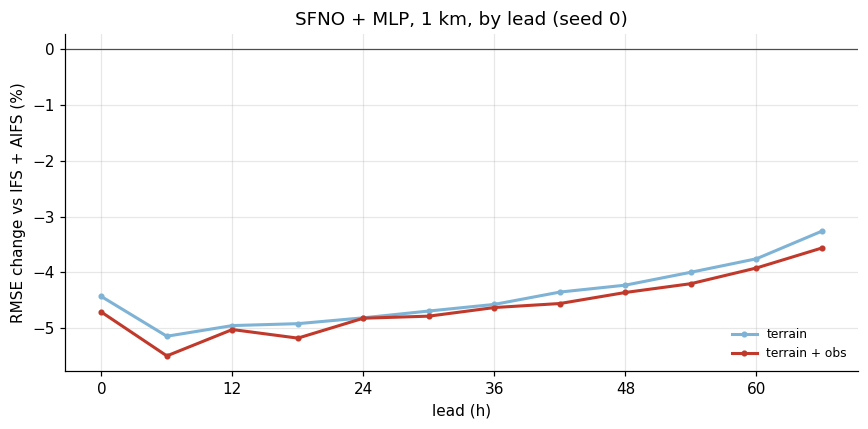

In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
for lab, p, col in [('terrain', 'sfno_terrain_g{k}_s{s}', '#7fb3d5'), ('terrain + obs', 'sfno_terrainobs_g{k}_s{s}', '#c0392b')]:
    ax.plot(L, res(p)[0], '-o', ms=3, lw=2, color=col, label=lab)
ax.set(xlabel='lead (h)', ylabel='RMSE change vs IFS + AIFS (%)', xticks=L[::2],
       title='SFNO + MLP, 1 km, by lead (seed 0)')
ax.axhline(0, color='0.3', lw=.8); ax.legend(fontsize=8)
plt.tight_layout()

## 6 · Training stations

More stations to learn from: *178* adds the SMHI and FMI stations north of 65° N (Sweden, Finland),
*196* also the Frost stations of Trøndelag. The extra stations get their own groups and are only
used for training; the score is on the same 99 stations as everywhere else. SFNO + MLP with 1 km
terrain, learning rate $10^{-3}$, seed 0; the grey band is the seed range of the 99-station model and
the dashed line its seed 0.

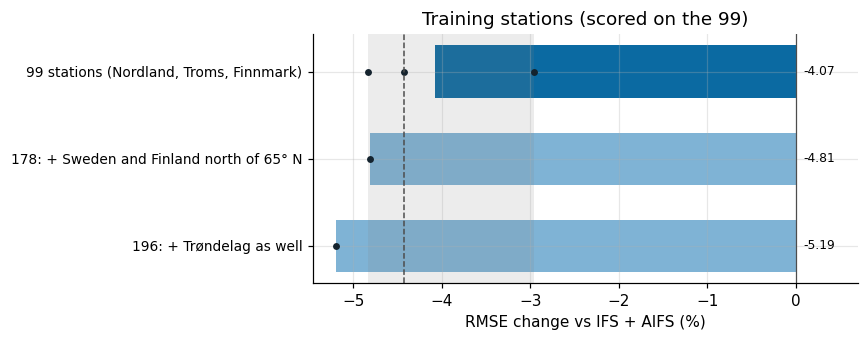

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.2))
bars(ax, [('99 stations (Nordland, Troms, Finnmark)', 'sfno_terrain_g{k}_s{s}'),
          ('178: + Sweden and Finland north of 65° N', 'sfno_terrain_g{k}_s{s}_ext'),
          ('196: + Trøndelag as well', 'sfno_terrain_g{k}_s{s}_all')],
     'Training stations (scored on the 99)', ref='sfno_terrain_g{k}_s{s}')
plt.tight_layout()

## 7 · All configurations

In [12]:
ALL = ([(f'learning rate · {lab} · {lr:g}', p, 'ecmwf') for lab, d in LRS.items() for lr, p in sorted(d.items())]
       + [('terrain · + 100 m station point · 0.001', 'sfno_terrain_g{k}_s{s}_t100', 'ecmwf')]
       + [(f'network · {lab}', p, 'ecmwf') for lab, p in NETS + STAGE1]
       + [(f'inputs · {lab} · four models', f'{m}_terrain_g{{k}}_s{{s}}_nwp_lr1e-05', 'nwp') for lab, m, _ in INP]
       + [(f'obs input · {lab}', f'sfno_terrainobs_g{{k}}_s{{s}}{sfx}', 'ecmwf') for lab, sfx in PAIRS]
       + [('obs input · MLP, 1 km', 'point_terrainobs_g{k}_s{s}', 'ecmwf'),
          ('stations · 178', 'sfno_terrain_g{k}_s{s}_ext', 'ecmwf'), ('stations · 196', 'sfno_terrain_g{k}_s{s}_all', 'ecmwf')])
seen = set()
ALL = [x for x in ALL if not ((x[1], x[2]) in seen or seen.add((x[1], x[2])))]   # each set of runs once
pd.DataFrame([row(*x) for x in ALL]).set_index('configuration').sort_values('mean (%)').round(2)

,seeds,mean (%),seed sd,+6 h,+24 h,+48 h,+66 h
configuration,,,,,,,
inputs · MLP · four models,3,-9.71,0.25,-12.73,-11.03,-8.13,-5.78
inputs · SFNO + MLP · four models,3,-9.03,0.19,-12.00,-10.19,-7.45,-5.37
inputs · FNO + MLP · four models,3,-8.86,0.38,-11.53,-10.24,-7.46,-5.16
stations · 196,1,-5.19,NaN,-5.94,-5.55,-4.89,-4.10
stations · 178,1,-4.81,NaN,-5.55,-5.18,-4.54,-3.71
"obs input · MLP, 1 km",1,-4.62,NaN,-5.31,-5.12,-4.36,-3.56
"obs input · SFNO + MLP, 1 km",1,-4.61,NaN,-5.50,-4.83,-4.36,-3.56
"learning rate · SFNO + MLP, 1 km terrain · 1e-05",3,-4.39,0.76,-4.98,-4.67,-4.16,-3.48
"learning rate · SFNO + MLP, 1 km terrain · 0.0001",1,-4.32,NaN,-4.90,-4.59,-4.11,-3.41


## Summary

Against the IFS + AIFS mean (vector RMSE 3.49 m/s):

* **Input forecasts matter most.** With IFS + GFS + MEPS + AROME-Arctic, the uncorrected mean is
  already −6.4 %; the corrected models reach −8.9 to −9.7 % (MLP best, seed spread 0.2–0.4). The
  gain is largest at short leads (−12.7 % at +6 h for the MLP) and shrinks to about −5.8 % at +66 h.
  With IFS + AIFS inputs the best model reaches −4.4 %.
* **Terrain descriptors bring the gain.** Without them, the first-stage operators (station
  obs-forecast as input) reach at most −0.9 %, and four of them are worse than no correction. With
  the 1 km descriptors every network improves on IFS + AIFS.
* **Network type (IFS + AIFS inputs).** SFNO + MLP is best (−4.4 %) and better than the MLP alone
  with each of the 3 seeds. FNO, TFNO and UNO are no better than the MLP, and the 1 km LocalNO on
  terrain patches is the weakest (−1.1 %). With the four-model inputs the MLP alone is best: the
  2.5 km models already carry the regional information that the operator adds for IFS + AIFS.
* **Learning rate has a small effect.** For SFNO + MLP the mean over seeds is −4.1 % at
  $10^{-3}$ to −4.4 % at $10^{-5}$. Paired by seed, $10^{-5}$ is better than $10^{-3}$ with every
  seed, by 0.2–0.4 percentage points. The seeds differ far more: seed 2 is about 1.5 points worse than
  seeds 0 and 1 at every rate.
* **Finer terrain does not help.** Every 100 m and 300 m variant is worse than the 1 km model with
  the same seed and rate, by 0.5 to 2.1 percentage points, in all 11 comparisons. The closest is
  the 300 m point and cell variant at $3\cdot10^{-5}$ (−4.15 % against −4.67 %). These variants were
  trained with seed 0 only; the consistent sign is the evidence, not any single difference. The
  likely reason is the same overfitting as in `01_training.ipynb`: the finer, station-specific inputs
  make the training stations easier to fit without carrying over to new ones.
* **Observations as input give no consistent gain.** Adding the other stations' obs-forecast at
  issue time changes the result by −1.2 to +1.1 points, with no consistent sign (seed 0).
* **More training stations may help.** Adding the Swedish and Finnish stations (178) gives −4.8 %,
  and adding Trøndelag as well (196) gives −5.2 %, against −4.4 % for seed 0 with 99 stations.
  This is the only change that improves on the 1 km model with the same seed. It lies inside the
  seed range, so it needs more seeds before it is a result.

**Website models:** the three networks with both input groups at $10^{-5}$. The MLP with the
four-model inputs is the default.